In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

SEED = 42                      # makes results repeatable
DATA_PATH = "WA_Fn-UseC_-HR-Employee-Attrition.csv"   # Adjusted to correct path

In [ ]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
print("Shape:", df.shape)
df.head()

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:
#understand the data
print(df["Attrition"].value_counts())
print()
print(df["Attrition"].value_counts(normalize=True).round(3))
print("\nMissing values in total:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Columns with only one value carry no information
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print("\nConstant columns:", constant_cols)

Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition
No     0.839
Yes    0.161
Name: proportion, dtype: float64

Missing values in total: 0
Duplicate rows: 0

Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


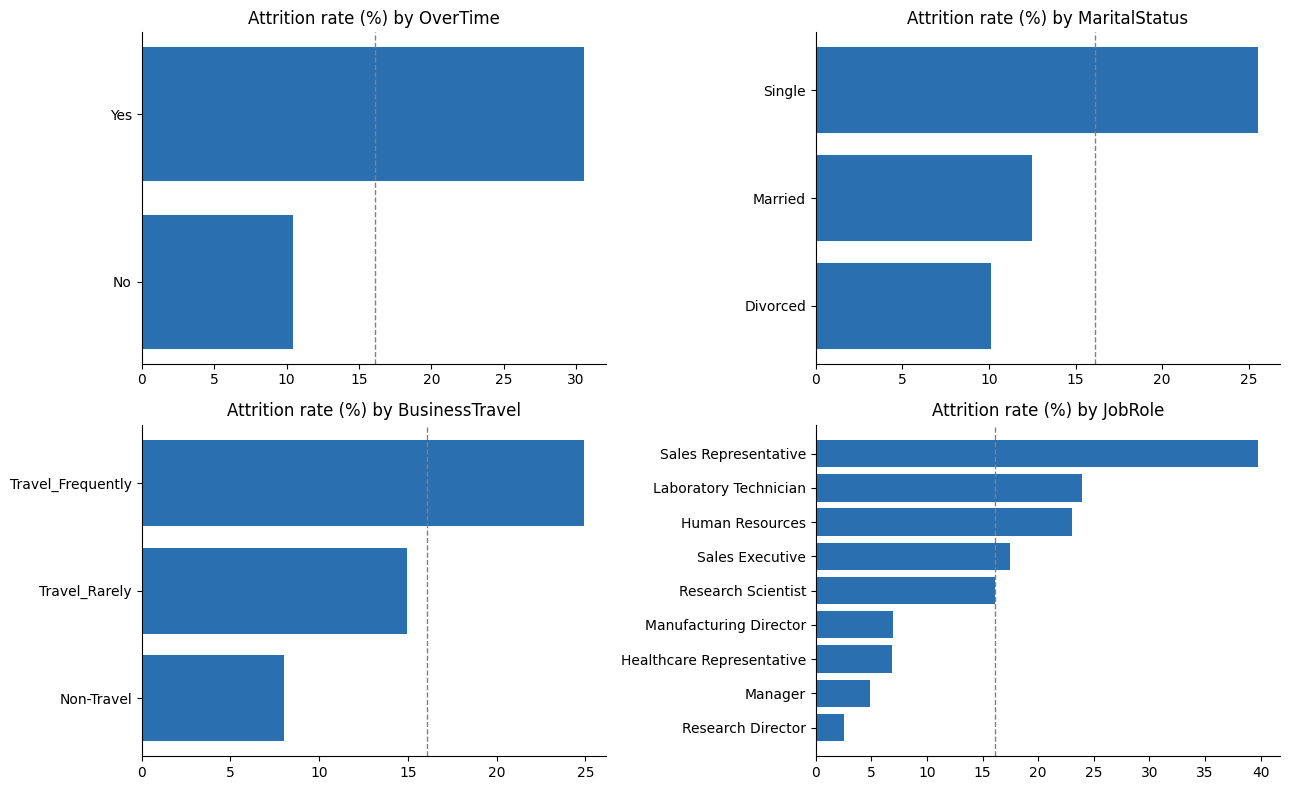

In [ ]:
def attrition_rate_by(col):
    return (df.assign(left=(df["Attrition"] == "Yes").astype(int))
              .groupby(col)["left"].mean().sort_values(ascending=False) * 100)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), ["OverTime", "MaritalStatus", "BusinessTravel", "JobRole"]):
    r = attrition_rate_by(col)
    ax.barh(r.index[::-1], r.values[::-1], color="#2a6fb0")
    ax.axvline(16.1, color="gray", ls="--", lw=1)            # overall rate
    ax.set_title(f"Attrition rate (%) by {col}")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
# Numeric features: compare average values of leavers vs stayers
num_cols = ["Age", "MonthlyIncome", "DistanceFromHome", "TotalWorkingYears",
            "YearsAtCompany", "YearsSinceLastPromotion", "YearsWithCurrManager"]
df.groupby("Attrition")[num_cols].mean().round(1).T

Attrition,No,Yes
Age,37.6,33.6
MonthlyIncome,6832.7,4787.1
DistanceFromHome,8.9,10.6
TotalWorkingYears,11.9,8.2
YearsAtCompany,7.4,5.1
YearsSinceLastPromotion,2.2,1.9
YearsWithCurrManager,4.4,2.9


In [ ]:
drop_cols = ["EmployeeCount", "EmployeeNumber", "Over18", "StandardHours"]
y = (df["Attrition"] == "Yes").astype(int)          # 1 = left
X = df.drop(columns=["Attrition"] + drop_cols)
print(X.shape, "| positives:", y.sum())

(1470, 30) | positives: 237


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "leavers:", y_train.sum())
print("Test: ", X_test.shape,  "leavers:", y_test.sum())

Train: (1176, 30) leavers: 190
Test:  (294, 30) leavers: 47


In [ ]:
numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
categorical_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, make_column_selector(dtype_include=np.number)),
    ("cat", categorical_pipe, make_column_selector(dtype_exclude=np.number)),
])

def make_model(clf):
    return Pipeline([("prep", preprocess), ("clf", clf)])

In [ ]:
baseline = make_model(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
pred = baseline.predict(X_test)
print(f"Baseline 'always No': accuracy = {accuracy_score(y_test, pred):.3f}, recall = {recall_score(y_test, pred):.3f}")

Baseline 'always No': accuracy = 0.840, recall = 0.000


In [ ]:
models = {
    "Logistic Regression": make_model(LogisticRegression(max_iter=3000, class_weight="balanced")),
    "Random Forest":       make_model(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                             min_samples_leaf=5, random_state=SEED, n_jobs=-1)),
    "Gradient Boosting":   make_model(HistGradientBoostingClassifier(class_weight="balanced", max_depth=3,
                                                                    learning_rate=0.05, random_state=SEED)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, model in models.items():
    roc = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    ap  = cross_val_score(model, X_train, y_train, cv=cv, scoring="average_precision")
    rows.append({"model": name, "ROC-AUC": roc.mean(), "ROC std": roc.std(), "PR-AUC": ap.mean()})
cv_results = pd.DataFrame(rows).set_index("model").round(3)
cv_results

,ROC-AUC,ROC std,PR-AUC
model,,,
Logistic Regression,0.827,0.028,0.606
Random Forest,0.804,0.033,0.563
Gradient Boosting,0.798,0.024,0.551


In [ ]:
grid = GridSearchCV(
    make_model(LogisticRegression(max_iter=3000, class_weight="balanced")),
    param_grid={"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    scoring="average_precision", cv=cv, n_jobs=-1)
grid.fit(X_train, y_train)
best_model = grid.best_estimator_
print("Best C:", grid.best_params_["clf__C"], "| CV PR-AUC:", round(grid.best_score_, 3))

Best C: 0.1 | CV PR-AUC: 0.63


In [ ]:
oof = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

def best_threshold(y_true, p, beta=1.0):
    prec, rec, thr = precision_recall_curve(y_true, p)
    prec, rec = prec[:-1], rec[:-1]
    f = (1 + beta**2) * prec * rec / np.maximum(beta**2 * prec + rec, 1e-12)
    return thr[np.argmax(f)], f.max()

thr_balanced, f1 = best_threshold(y_train, oof, beta=1)   # balance precision and recall
thr_recall,   f2 = best_threshold(y_train, oof, beta=2)   # favour recall (catch more leavers)
print(f"Balanced threshold (F1): {thr_balanced:.2f}")
print(f"Recall-focused threshold (F2): {thr_recall:.2f}")
threshold = thr_balanced        # <- switch to thr_recall if missing a leaver is costlier than a false alarm

Balanced threshold (F1): 0.69
Recall-focused threshold (F2): 0.58


In [ ]:
proba = best_model.predict_proba(X_test)[:, 1]
pred = (proba >= threshold).astype(int)

print(f"ROC-AUC : {roc_auc_score(y_test, proba):.3f}")
print(f"PR-AUC  : {average_precision_score(y_test, proba):.3f}   (random guessing = {y_test.mean():.3f})")
print(f"\nAt threshold {threshold:.2f}:")
print(classification_report(y_test, pred, target_names=["Stay", "Leave"]))

# What if HR only contacts the 10% highest-risk employees?
k = int(len(y_test) * 0.10)
top = np.argsort(-proba)[:k]
print(f"Top 10% highest-risk employees contain {y_test.iloc[top].sum() / y_test.sum():.0%} of all leavers")

ROC-AUC : 0.812
PR-AUC  : 0.588   (random guessing = 0.160)

At threshold 0.69:
              precision    recall  f1-score   support

        Stay       0.90      0.92      0.91       247
       Leave       0.54      0.47      0.50        47

    accuracy                           0.85       294
   macro avg       0.72      0.70      0.71       294
weighted avg       0.84      0.85      0.85       294

Top 10% highest-risk employees contain 40% of all leavers


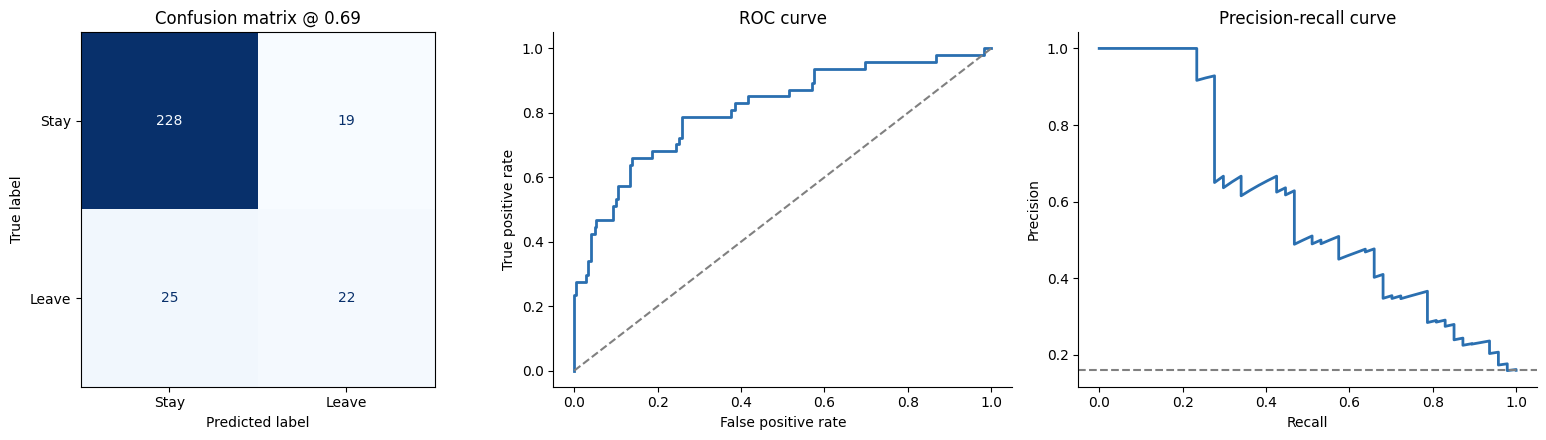

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stay", "Leave"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title(f"Confusion matrix @ {threshold:.2f}")

fpr, tpr, _ = roc_curve(y_test, proba)
ax[1].plot(fpr, tpr, color="#2a6fb0", lw=2); ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")

p, r, _ = precision_recall_curve(y_test, proba)
ax[2].plot(r, p, color="#2a6fb0", lw=2); ax[2].axhline(y_test.mean(), ls="--", color="gray")
ax[2].set(title="Precision-recall curve", xlabel="Recall", ylabel="Precision")

for a in ax[1:]: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

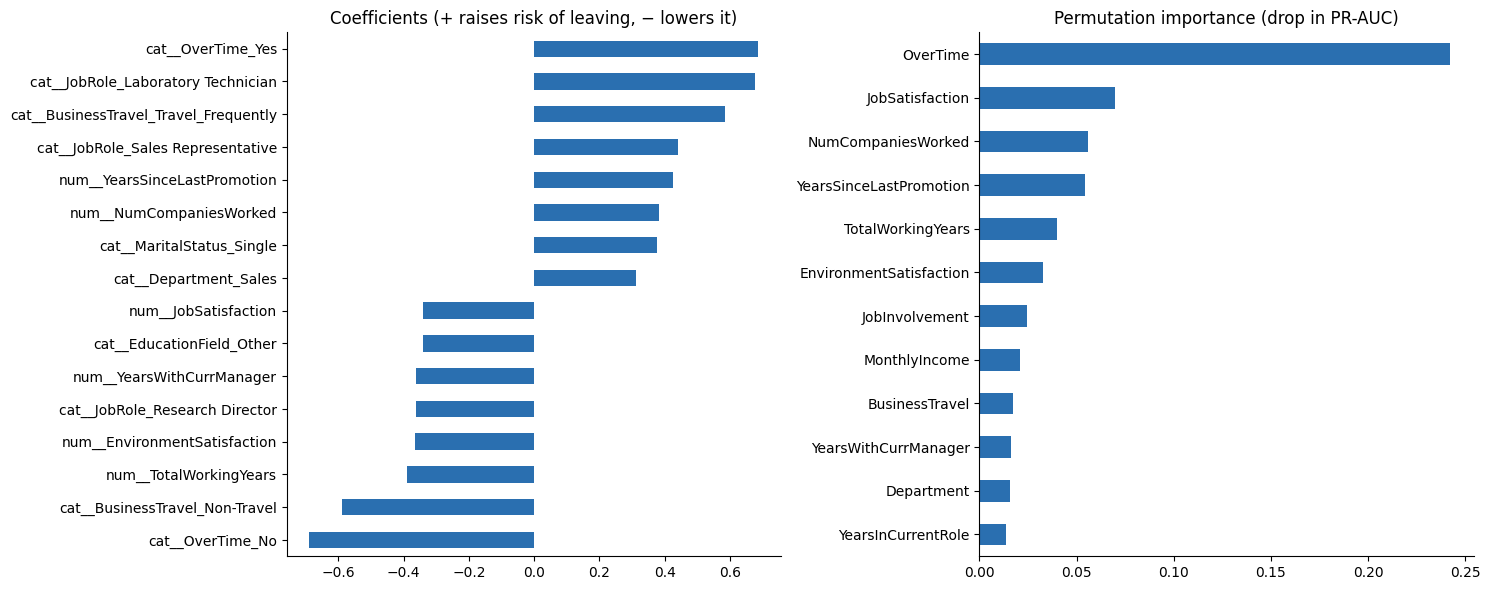

In [ ]:
names = best_model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(best_model.named_steps["clf"].coef_[0], index=names).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
pd.concat([coefs.head(8), coefs.tail(8)]).plot.barh(ax=ax[0], color="#2a6fb0")
ax[0].set_title("Coefficients (+ raises risk of leaving, − lowers it)")

pi = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                            n_repeats=15, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values().tail(12)
imp.plot.barh(ax=ax[1], color="#2a6fb0")
ax[1].set_title("Permutation importance (drop in PR-AUC)")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [ ]:
joblib.dump({"model": best_model, "threshold": float(threshold), "columns": list(X.columns)}, "attrition_model.joblib")

# Later, or in another script:
bundle = joblib.load("attrition_model.joblib")

def predict_attrition(new_df):
    p = bundle["model"].predict_proba(new_df[bundle["columns"]])[:, 1]
    out = new_df.copy()
    out["attrition_probability"] = p.round(3)
    out["predicted_to_leave"] = (p >= bundle["threshold"]).astype(int)
    return out

# Demo: score 5 employees from the test set
predict_attrition(X_test.head(5))[["Age", "JobRole", "OverTime", "MonthlyIncome", "attrition_probability", "predicted_to_leave"]]

,Age,JobRole,OverTime,MonthlyIncome,attrition_probability,predicted_to_leave
1061,24,Sales Representative,No,2033,0.368,0
891,44,Research Scientist,No,2011,0.039,0
456,31,Manager,No,11557,0.481,0
922,44,Manager,No,19190,0.038,0
69,36,Research Scientist,Yes,3388,0.657,0


In [ ]:
def add_features(d):
    d = d.copy()
    d["IncomePerJobLevel"]  = d["MonthlyIncome"] / d["JobLevel"].clip(lower=1)
    d["TenureRatio"]        = d["YearsAtCompany"] / (d["TotalWorkingYears"] + 1)
    d["PromotionLag"]       = d["YearsSinceLastPromotion"] / (d["YearsAtCompany"] + 1)
    d["SatisfactionMean"]   = d[["EnvironmentSatisfaction", "JobSatisfaction",
                                 "RelationshipSatisfaction", "WorkLifeBalance"]].mean(axis=1)
    return d

X_train_fe, X_test_fe = add_features(X_train), add_features(X_test)
fe_model = make_model(LogisticRegression(max_iter=3000, class_weight="balanced", C=grid.best_params_["clf__C"]))
base = cross_val_score(best_model, X_train, y_train, cv=cv, scoring="roc_auc").mean()
fe   = cross_val_score(fe_model, X_train_fe, y_train, cv=cv, scoring="roc_auc").mean()
print(f"CV ROC-AUC without engineered features: {base:.3f}")
print(f"CV ROC-AUC with engineered features:    {fe:.3f}")

CV ROC-AUC without engineered features: 0.831
CV ROC-AUC with engineered features:    0.831
